# Advanced RAG
query_rewriter → multi_query_generator → retrieval_layer (Vector + BM25 + Web) → re_ranker → augment_context → LLM → self_corrector → final_answer

In [7]:
# step 1 (install libraries)
%pip install --upgrade langchain-community langchain-text-splitters langchain-ollama langchain-groq langgraph langgraph-checkpoint-sqlite chromadb pypdf python-dotenv rank_bm25 sentence-transformers tavily-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
# step 2 (imports)
import os                                                       # to read environment variables
import re                                                       # to read verdict lines from LLM replies
import time                                                     # to wait before retrying
import sqlite3                                                  # for permanent chat storage
import operator                                                 # gives "add" so history lists grow instead of being replaced
from typing import TypedDict, Annotated                         # to describe the shape of our state
from dotenv import load_dotenv                                  # reads the .env file
from langchain_community.document_loaders import PyPDFLoader   # reads the PDF page by page
from langchain_text_splitters import RecursiveCharacterTextSplitter  # cuts long text into small chunks
from langchain_ollama import OllamaEmbeddings                   # text -> numbers (runs locally)
from langchain_community.vectorstores import Chroma             # the vector database (semantic search)
from langchain_community.retrievers import BM25Retriever        # keyword search (lexical search)
from sentence_transformers import CrossEncoder                  # the re-ranker model
from langchain_groq import ChatGroq                             # the LLM on Groq
from groq import RateLimitError                                 # the 429 "too many tokens" error from Groq
from tavily import TavilyClient                                 # web search (external info)
from langchain_core.messages import SystemMessage, HumanMessage # message types for the LLM
from langgraph.graph import StateGraph, START, END              # graph builder + start and end points
from langgraph.checkpoint.sqlite import SqliteSaver             # saves graph state into a SQLite file

In [9]:
# cache setup (step 2 se pehle chalana zaroori hai)
import os

for k in ["HF_HOME", "HF_HUB_CACHE", "HUGGINGFACE_HUB_CACHE",
          "TRANSFORMERS_CACHE", "SENTENCE_TRANSFORMERS_HOME"]:
    os.environ.pop(k, None)

CACHE = r"C:\hf_cache"
os.makedirs(CACHE, exist_ok=True)
os.environ["HF_HOME"] = CACHE
print("Cache folder:", CACHE)

Cache folder: C:\hf_cache


In [10]:
# step 3 (settings)
load_dotenv(override=True)                                      # loads GROQ_API_KEY and TAVILY_API_KEY from .env
PDF_FILE        = "text_medical.pdf"                            # the PDF in your project folder
OLLAMA_URL      = "http://localhost:11434"                      # Ollama runs here (for embeddings)
CHROMA_FOLDER   = "./chroma_db_advanced"                        # vector folder (created on first run)
NUM_QUERIES     = 3                                             # multi-query: how many extra versions of the question
VECTOR_K        = 4                                             # chunks per query from the vector DB
BM25_K          = 4                                             # chunks per query from BM25 keyword search
WEB_RESULTS     = 3                                             # web pages from Tavily
RERANK_TOP      = 5                                             # re-ranker keeps only the best 5
MAX_REFINES     = 1                                             # self_corrector: times the LLM may fix its answer
MAX_RETRIEVALS  = 1                                             # self_corrector: times we may go back and search again
HISTORY_TURNS   = 3                                             # only the last 3 Q/A pairs go to the LLM

TAVILY_KEY = os.environ.get("TAVILY_API_KEY", "")               # empty = web search is skipped
web_client = TavilyClient(api_key=TAVILY_KEY) if TAVILY_KEY else None

print("Groq key  :", os.environ["GROQ_API_KEY"][:8] + "...")
print("Web search:", "ON (Tavily)" if web_client else "OFF (only book search)")
print("Ready!")

Groq key  : gsk_aTPd...
Web search: OFF (only book search)
Ready!


In [11]:
# step 4 (load and split the pdf)
documents = PyPDFLoader(PDF_FILE).load()                        # one Document per page

splitter = RecursiveCharacterTextSplitter(                      # create the text cutter
    chunk_size    = 1000,                                       # each chunk is at most 1000 characters
    chunk_overlap = 200,                                        # 200 characters shared between neighbours
)
chunks = splitter.split_documents(documents)                    # cut every page into chunks

print("Pages:", len(documents), "| Chunks:", len(chunks))       # e.g. Pages: 56 | Chunks: 257

Pages: 56 | Chunks: 257


In [12]:
# step 5 (store the chunks, then load the folder for retrieval)
embedding_model = OllamaEmbeddings(model="embeddinggemma", base_url=OLLAMA_URL)   # text -> numbers converter

if not os.path.exists(CHROMA_FOLDER):                           # first run: folder not created yet
    print("Storing", len(chunks), "chunks in", CHROMA_FOLDER, "... (1-2 minutes)")
    vectorstore = Chroma.from_documents(                        # embed every chunk and save to disk
        documents          = chunks,                            # the chunks from step 4
        embedding          = embedding_model,                   # same embedding model used for questions later
        persist_directory  = CHROMA_FOLDER,                     # folder where the vectors are saved
    )
    print("Stored:", vectorstore._collection.count(), "chunks") # confirm
else:                                                           # next runs: folder already exists
    vectorstore = Chroma(                                       # just load the saved folder, no re-embedding
        persist_directory  = CHROMA_FOLDER,                     # folder on disk
        embedding_function = embedding_model,                   # needed to embed the questions
    )
    print("Loaded", CHROMA_FOLDER, "with", vectorstore._collection.count(), "chunks")

# quick retrieval test: proves the loaded folder can be searched
test = vectorstore.similarity_search("fever", k=2)              # 2 closest chunks
for d in test:
    print(f"[page {d.metadata.get('page', 0) + 1}]", d.page_content[:120].replace("\n", " "), "...")

Loaded ./chroma_db_advanced with 257 chunks
[page 28] especially in children.  Place the person in a cool area and remove all clothing. Fan the person. Pour cool, not cold, w ...
[page 28] illness. A high fever above 39°C can be dangerous, especially for small children.  When a person has a fever, remove mos ...


In [13]:
# step 6 (BM25 keyword index + re-ranker model)
bm25 = BM25Retriever.from_documents(chunks)                     # keyword index built from the same chunks (in memory, fast)
bm25.k = BM25_K                                                 # chunks per query

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", cache_folder=CACHE)  # small re-ranker (~90 MB, downloads once, runs on CPU)
print("BM25 ready with", len(chunks), "chunks | Re-ranker loaded")

The Transformer `cache_dir` argument is deprecated. Please pass `cache_dir` via `model_kwargs`, `processor_kwargs`, and/or `config_kwargs` instead.
Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2682.84it/s]


BM25 ready with 257 chunks | Re-ranker loaded


In [14]:
# step 7 (LLMs)
llm = ChatGroq(                                                 # WRITER: rewrite, multi-query, answer
    model            = "openai/gpt-oss-120b",                   # strong writer
    temperature      = 0.1,                                     # steady answers
    max_tokens       = 1500,                                    # room to think and answer
    reasoning_effort = "low",                                   # short thinking
)

check_llm = ChatGroq(                                           # SELF-CORRECTOR: checks the answer (different model family)
    model            = "qwen/qwen3.8-27b",                      # independent from the GPT writer
    temperature      = 0.0,                                     # consistent verdicts
    max_tokens       = 900,                                     # must stay under Qwen's 1000 output-tokens-per-minute limit
    reasoning_effort = "none",                                  # instruct mode: no hidden thinking eating the 900 tokens
)
print("Writer:", llm.model_name, "| Self-corrector:", check_llm.model_name)

Writer: openai/gpt-oss-120b | Self-corrector: qwen/qwen3.8-27b


In [15]:
# step 8 (state)
class AdvState(TypedDict):                                      # everything the graph remembers while running
    question: str                                               # user_query: the original question
    rewritten: str                                              # query_rewriter output
    queries: list                                               # multi_query_generator output (rewritten + versions)
    candidates: list                                            # everything the retrieval layer found
    top_chunks: list                                            # re-ranker output (best RERANK_TOP)
    context: str                                                # augment_context output
    generation: str                                             # the answer
    verdict: str                                                # "correct" / "refine" / "retrieve_again"
    feedback: str                                               # what the self_corrector wants fixed
    refines: int                                                # answer fixes used
    retrievals: int                                             # extra retrieval rounds used
    history: Annotated[list, operator.add]                      # past Q/A lines; operator.add = append, saved in SQLite

In [16]:
# step 9 (prompts)
SAFETY_LINE = "This is general guidance, not a diagnosis; if you are worried or it gets worse, please see a health worker."

# Prompt 1: query_rewriter - clean, expand and fix the question
REWRITE_PROMPT = """Rewrite the user's health message into ONE clear, complete search question for a village health book.
- Fix spelling, remove filler words, expand short forms (BP -> blood pressure, sugar -> diabetes).
- Replace everyday phrases with book words ("loose motions" -> diarrhea, "body is burning" -> fever).
- If it is a follow-up (e.g. "what about children?"), use the CHAT HISTORY to add the missing topic.
- If FEEDBACK is given, the last search failed: use it to write a better question.
- Reply with the rewritten question only."""

# Prompt 2: multi_query_generator - different angles of the same question
MULTI_QUERY_PROMPT = f"""Write {NUM_QUERIES} different search queries for the QUESTION, each from a different angle
(for example: symptoms, treatment / what to do, danger signs / when to see a health worker).
Short keyword-style queries. One query per line, no numbers, no extra text."""

# Prompt 3: LLM - answer ONLY from the context
GENERATE_PROMPT = f"""You are a Village Health Guide Assistant.
Answer the QUESTION using ONLY the CONTEXT. Never use your own knowledge.
Each context block starts with its source: [page N] from the health book or [web: link] from the internet.

STRICT RULES
- Every fact you write must be written in the CONTEXT. Prefer the health book over web.
- Do NOT add numbers, temperatures, days, medicine names, doses, or warnings that are not in the CONTEXT.
- Do NOT change who a medicine is for (children / adults / pregnant women).
- Include danger signs (when to get help) if the CONTEXT has them.
- If the CONTEXT does not answer the question, say: I don't know based on the available sources.
- If FEEDBACK is given, fix exactly those problems.

FORMAT
- Write like a person talking, in 3 to 6 short sentences. No bold, no headings, no lists.
- After your answer, write this exact sentence: {SAFETY_LINE}
- Last line: the sources used, like: Source: page 28, web: https://example.org"""

# Prompt 4: self_corrector - verify + decide how to fix
CORRECTOR_PROMPT = f"""You are a strict self-corrector. You get a QUESTION, an ANSWER and the CONTEXT.
IGNORE the line "{SAFETY_LINE}" and the "Source: ..." line.

1. Split the ANSWER into factual claims. For each, write SUPPORTED or UNSUPPORTED (must be clearly in the CONTEXT, numbers exact).
2. Decide:
   correct        - every claim supported AND the answer tells the user what to do about their problem
   refine         - the CONTEXT has the right information, but the ANSWER has unsupported claims or missed parts
   retrieve_again - the CONTEXT itself does not contain the information needed

Output format:
SUPPORTED - <claim>
UNSUPPORTED - <claim>
FEEDBACK: <one sentence: what to fix, or what information is missing>
VERDICT: correct | refine | retrieve_again"""

In [17]:
# step 10 (helpers)
def safe_invoke(model, messages, tries=3, wait=25):             # calls an LLM; waits and retries if rate-limited
    for attempt in range(tries):
        try:
            return (model.invoke(messages).content or "")       # success: return the text (never None)
        except RateLimitError:                                  # hit the per-minute limit
            if attempt == tries - 1:
                raise
            print(f"   [wait]     rate limit hit, waiting {wait}s...")
            time.sleep(wait)


def recent_history(state: AdvState) -> str:                     # builds a short history text for the LLM
    lines = state.get("history", [])[-HISTORY_TURNS * 2:]
    return "\n".join(lines) if lines else "(no earlier messages)"


def add_safety_line(answer: str) -> str:                        # inserts SAFETY_LINE before "Source:" if the LLM forgot it
    if SAFETY_LINE in answer:
        return answer
    lines  = answer.strip().splitlines()
    source = [l for l in lines if l.strip().lower().startswith("source")]
    body   = [l for l in lines if l not in source]
    return "\n".join(body + [SAFETY_LINE] + source)


def as_block(doc) -> str:                                       # Document -> "[page N]\ntext"
    return f"[page {doc.metadata.get('page', 0) + 1}]\n{doc.page_content}"

In [18]:
# step 11 (nodes)

# NODE 2 query_rewriter: improve & expand the question (uses feedback when we come back here)
def query_rewriter_node(state: AdvState):
    text = (f"CHAT HISTORY:\n{recent_history(state)}\n\nMESSAGE: {state['question']}"
            f"\n\nFEEDBACK: {state.get('feedback') or '(none)'}")
    rewritten = safe_invoke(llm, [SystemMessage(content=REWRITE_PROMPT),
                                  HumanMessage(content=text)]).strip() or state["question"]
    print("   [rewrite]  ", rewritten)
    return {"rewritten": rewritten}


# NODE 3 multi_query_generator: create several queries from different angles
def multi_query_node(state: AdvState):
    reply = safe_invoke(llm, [SystemMessage(content=MULTI_QUERY_PROMPT),
                              HumanMessage(content=f"QUESTION: {state['rewritten']}")])
    extra = [l.strip("-• ").strip() for l in reply.splitlines() if l.strip()][:NUM_QUERIES]
    queries = [state["rewritten"]] + extra                      # rewritten question + the new versions
    print("   [multi]    ", queries)
    return {"queries": queries}


# NODE 4 retrieval_layer: hybrid search = Vector DB + BM25 keyword + Web, for every query
def retrieval_node(state: AdvState):
    found = []
    for q in state["queries"]:
        found += [as_block(d) for d in vectorstore.similarity_search(q, k=VECTOR_K)]   # semantic search
        found += [as_block(d) for d in bm25.invoke(q)]                               # keyword search
    if web_client:                                              # external info (one search is enough)
        for r in web_client.search(state["rewritten"], max_results=WEB_RESULTS).get("results", []):
            found.append(f"[web: {r['url']}]\n{r.get('content', '')}")
    unique = list(dict.fromkeys(found))                         # remove duplicates, keep order
    print(f"   [retrieve]  {len(found)} results -> {len(unique)} unique")
    return {"candidates": unique}


# NODE 5 re_ranker: cross-encoder scores (question, chunk) pairs and keeps the best
def re_ranker_node(state: AdvState):
    pairs  = [(state["rewritten"], c) for c in state["candidates"]]   # question + each chunk
    scores = reranker.predict(pairs)                            # higher = more relevant
    ranked = [c for _, c in sorted(zip(scores, state["candidates"]), key=lambda x: x[0], reverse=True)]
    top    = ranked[:RERANK_TOP]
    print("   [re-rank]   kept top", len(top), "|", ", ".join(t.split("\n")[0] for t in top))
    return {"top_chunks": top}


# NODE 6 augment_context: combine + format the best chunks for the prompt
def augment_context_node(state: AdvState):
    blocks = [f"--- context {i+1} ---\n{c}" for i, c in enumerate(state["top_chunks"])]   # numbered, with source
    return {"context": "\n\n".join(blocks)}


# NODE 7 LLM: generate the initial answer (or a refined one if feedback is present)
def llm_node(state: AdvState):
    fb   = state.get("feedback") if state.get("verdict") == "refine" else ""
    text = (f"QUESTION: {state['question']}\n\nCONTEXT:\n{state['context']}"
            + (f"\n\nFEEDBACK:\n{fb}\n\nPREVIOUS ANSWER:\n{state['generation']}" if fb else ""))
    reply = safe_invoke(llm, [SystemMessage(content=GENERATE_PROMPT),
                              HumanMessage(content=text)])
    return {"generation": add_safety_line(reply)}


# NODE 8 self_corrector: verify + fix errors (decides: correct / refine / retrieve_again)
def self_corrector_node(state: AdvState):
    text  = (f"QUESTION: {state['question']}\n\nANSWER:\n{state['generation']}"
             f"\n\nCONTEXT:\n{state['context']}")
    reply = safe_invoke(check_llm, [SystemMessage(content=CORRECTOR_PROMPT),
                                    HumanMessage(content=text)]).strip()
    print("   [check]\n" + "\n".join("      " + l for l in reply.splitlines()))
    m  = re.search(r"VERDICT:\s*(correct|refine|retrieve_again)", reply, re.IGNORECASE)
    fb = re.search(r"FEEDBACK:\s*(.+)", reply, re.IGNORECASE)
    return {"verdict": m.group(1).lower() if m else "refine",   # unclear reply -> try to refine
            "feedback": fb.group(1).strip() if fb else ""}


# ROUTER after self_corrector: Correct -> final | refine -> LLM | bad retrieval -> query_rewriter
def route_after_corrector(state: AdvState):
    if state["verdict"] == "correct":
        return "final_answer"
    if state["verdict"] == "refine" and state["refines"] < MAX_REFINES:
        return "count_refine"                                   # "if not correct (refine answer)"
    if state["retrievals"] < MAX_RETRIEVALS:
        return "count_retrieval"                                # "use feedback for better retrieval & rewriting"
    return "no_answer_found"                                    # limits used up: stay safe


# small counter nodes, so the loops can never run forever
def count_refine_node(state: AdvState):
    return {"refines": state["refines"] + 1}

def count_retrieval_node(state: AdvState):
    return {"retrievals": state["retrievals"] + 1, "verdict": "retrieve_again"}


# NODE 9 final_answer: complete & accurate
def final_answer_node(state: AdvState):
    return {"generation": state["generation"].strip()}


def no_answer_found_node(state: AdvState):                      # honest fallback
    return {"generation": "I don't know based on the available sources. Please ask a health worker or visit a clinic."}


def save_memory_node(state: AdvState):                          # adds this Q/A to history (stored in SQLite)
    return {"history": [f"User: {state['question']}", f"Assistant: {state['generation']}"]}

In [19]:
# step 12 (build the graph)
builder = StateGraph(AdvState)

builder.add_node("query_rewriter", query_rewriter_node)
builder.add_node("multi_query_generator", multi_query_node)
builder.add_node("retrieval_layer", retrieval_node)
builder.add_node("re_ranker", re_ranker_node)
builder.add_node("augment_context", augment_context_node)
builder.add_node("LLM", llm_node)
builder.add_node("self_corrector", self_corrector_node)
builder.add_node("count_refine", count_refine_node)
builder.add_node("count_retrieval", count_retrieval_node)
builder.add_node("final_answer", final_answer_node)
builder.add_node("no_answer_found", no_answer_found_node)
builder.add_node("save_memory", save_memory_node)

builder.add_edge(START, "query_rewriter")                       # user_query goes in here
builder.add_edge("query_rewriter", "multi_query_generator")
builder.add_edge("multi_query_generator", "retrieval_layer")
builder.add_edge("retrieval_layer", "re_ranker")
builder.add_edge("re_ranker", "augment_context")
builder.add_edge("augment_context", "LLM")
builder.add_edge("LLM", "self_corrector")
builder.add_conditional_edges("self_corrector", route_after_corrector,
    {"final_answer": "final_answer", "count_refine": "count_refine",
     "count_retrieval": "count_retrieval", "no_answer_found": "no_answer_found"})
builder.add_edge("count_refine", "LLM")                         # small loop: refine the answer
builder.add_edge("count_retrieval", "query_rewriter")           # big loop: feedback -> better retrieval
builder.add_edge("final_answer", "save_memory")
builder.add_edge("no_answer_found", "save_memory")
builder.add_edge("save_memory", END)

conn = sqlite3.connect("advanced_memory.db", check_same_thread=False)   # open/create the SQLite file
memory = SqliteSaver(conn)                                      # checkpointer that writes state to SQLite
advanced_rag = builder.compile(checkpointer=memory)
print("Advanced RAG ready!")

Advanced RAG ready!


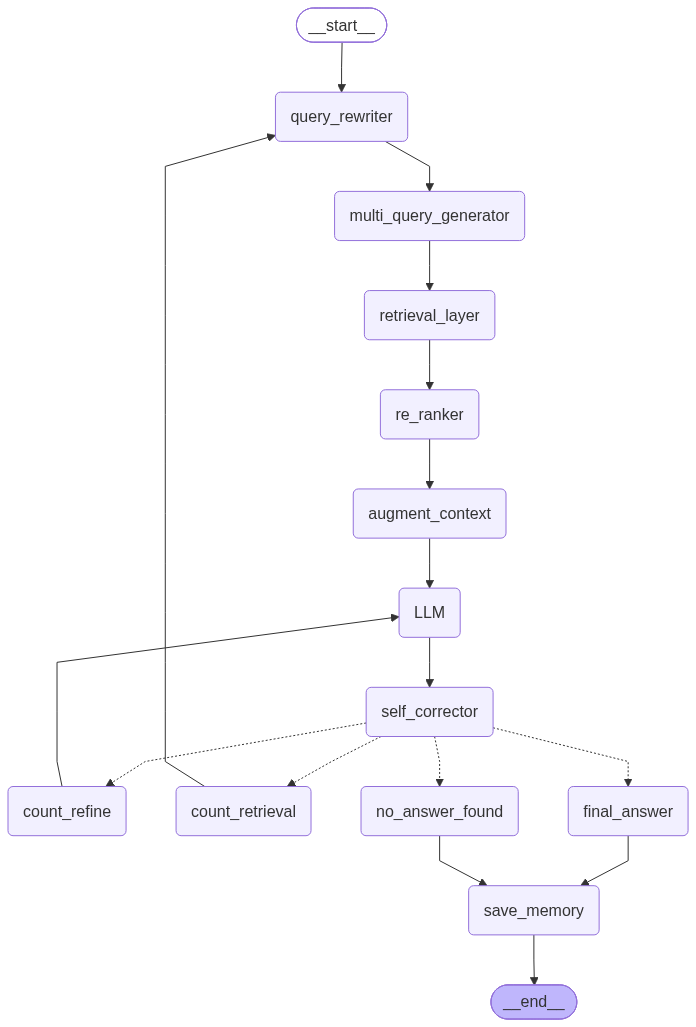

In [20]:
# step 13 (draw the graph)
from IPython.display import Image, display

try:
    display(Image(advanced_rag.get_graph().draw_mermaid_png())) # draw as image (needs internet)
except Exception:
    print(advanced_rag.get_graph().draw_mermaid())              # text version

In [21]:
# step 14 (ask function)
def ask(q, thread="chat1"):                                     # same thread = remembers past chats
    config  = {"configurable": {"thread_id": thread}, "recursion_limit": 40}
    payload = {"question": q, "rewritten": "", "queries": [], "candidates": [], "top_chunks": [],
               "context": "", "generation": "", "verdict": "", "feedback": "",
               "refines": 0, "retrievals": 0}                   # fresh values; history is kept
    print("You   :", q)
    answer = ""
    for chunk in advanced_rag.stream(payload, config=config, stream_mode="updates"):
        for node, update in chunk.items():
            update = update or {}
            if node == "LLM":
                print("   [LLM]       answer written")
            elif node == "self_corrector":
                print("   [verdict]  ", update["verdict"])
            elif node == "count_refine":
                print("   [loop]      refining the answer")
            elif node == "count_retrieval":
                print("   [loop]      back to query_rewriter with feedback")
            elif node == "final_answer":
                print("   [final]     answer accepted")
            elif node == "no_answer_found":
                print("   [not_found] no answer in the sources")
            if update.get("generation"):
                answer = update["generation"]
    print("Agent :", answer, "\n")

In [22]:
# step 15 (chat loop)
while True:                                                     # keep chatting until you type exit
    q = input("You : ")
    if q.lower() == "exit":
        break
    ask(q)

You   : hyy
   [rewrite]   What health information are you seeking?
   [multi]     ['What health information are you seeking?', 'common symptoms of flu and when to see a doctor', 'dietary guidelines for managing high blood pressure', 'mental health resources for stress relief and coping strategies']
   [retrieve]  32 results -> 25 unique
   [re-rank]   kept top 5 | [page 3], [page 1], [page 3], [page 15], [page 25]
   [LLM]       answer written
   [check]
      SUPPORTED - I don't know based on the available sources.
      UNSUPPORTED - This is general guidance, not a diagnosis; if you are worried or it gets worse, please see a health worker.
      UNSUPPORTED - Source: page 3, page 1, page 3, page 15, page 25
      FEEDBACK: The question "hyy" is unintelligible, so the answer correctly states it cannot be answered, but it includes unsupported medical disclaimers and source citations that are not present in the context or relevant to the lack of a question.
      VERDICT: refine
   [ve